In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

def getMcRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int        
    return hist, errs, bins

In [4]:
observables1 = ['pt','b','w','reject','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','rejects','y1s','y2s','phi1s','phi2s']
 
df_allreco = applyCut(getData(observables1+observabless1, '/gpfs/gibbs/project/havener/ys668/other_output/rc/all0615_chargedrc.root',\
                              "MatchedTree"), 'pts>15 and bs!=-9 and reject<=0 and rejects<=0')
df_allreco = applyCut(df_allreco, 'not (pts>25 and w>4e-9)') # removes one high weight jet

In [5]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

In [5]:
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [6]:
w_array = np.unique(df_allreco['w'])

In [7]:
df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25) & (df_allfake.ws<1e-9)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)] ]

In [8]:
rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getMcRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getMcRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [9]:
observables1 = ['pt','m','q2','rg','zg','mg','b']
file1 = uproot.open('/gpfs/gibbs/project/havener/ys668/other_output/rc/data0816_fake.root')
tree = file1["ResultTree"].arrays(observables1, library='np')
df = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df = applyCut(df, 'pts>15 and bs!=-9 and bs!=0')

In [10]:
df_20 = applyCut(df, '20 < pts < 25')
df_25 = applyCut(df, '25 < pts < 30')
df_30 = applyCut(df, '30 < pts < 40')
data_rc_20, data_rc_err_20 = getRcAndErr(df_20, 'bs')
data_rc_25, data_rc_err_25 = getRcAndErr(df_25, 'bs')
data_rc_30, data_rc_err_30 = getRcAndErr(df_30, 'bs')

In [11]:
df0 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_50pthat_rc_random.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_45pthat50_rc_random.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_40pthat45_rc_random.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_35pthat40_rc_random.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_30pthat35_rc_random.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_25pthat30_rc_random.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_20pthat25_rc_random.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_15pthat20_rc_random.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_11pthat15_rc_random.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [13]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8])
df_herwig = df[['pt','event_scale','b_ch','w']]

In [18]:
df_herwig = applyCut(df_herwig, 'pt>5 and b_ch != -9')

In [19]:
w_array = np.unique(df_herwig['w'])

In [20]:
df_herwig_pt_array = [ df_herwig[(df_herwig.pt>15) & (df_herwig.pt<20)],\
                       df_herwig[(df_herwig.pt>20) & (df_herwig.pt<25)],\
                       df_herwig[(df_herwig.pt>25) & (df_herwig.pt<30)],\
                       df_herwig[(df_herwig.pt>30) & (df_herwig.pt<40)] ]

In [21]:
rc_herwig_b_vs_pt_array = []
rc_err_herwig_b_vs_pt_array = []
for i in range(0, len(df_herwig_pt_array)):
    rc_herwig_b_vs_pt_array.append(getMcRcAndErr(df_herwig_pt_array[i], 'b_ch')[0])
    rc_err_herwig_b_vs_pt_array.append(getMcRcAndErr(df_herwig_pt_array[i], 'b_ch')[1])

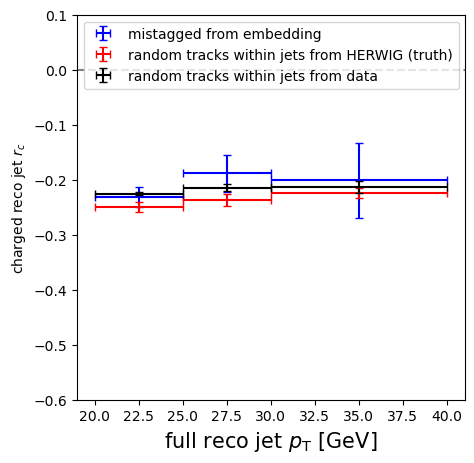

In [23]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:], capsize=3, color='b', ls='none', label='mistagged from embedding')
plt.errorbar([22.5, 27.5, 35], rc_herwig_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_herwig_b_vs_pt_array[1:], capsize=3, color='r', ls='none', label='random tracks within jets from HERWIG (truth)')
plt.errorbar([22.5, 27.5, 35], [data_rc_20, data_rc_25, data_rc_30], xerr=[2.5, 2.5, 5], yerr=[data_rc_err_20, data_rc_err_25, data_rc_err_30], capsize=3, ls='none', label='random tracks within jets from data', color='k')
plt.xlabel('full reco jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged reco jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [14]:
[data_rc_20, data_rc_25, data_rc_30]

[-0.22518997953719813, -0.21441642135412523, -0.2129313872595826]

In [15]:
[data_rc_err_20, data_rc_err_25, data_rc_err_30]

[0.002925290181545458, 0.006160481432193258, 0.01141150183243689]

In [24]:
rc_herwig_b_vs_pt_array[1:]

[-0.24935853643610195, -0.2364622721387403, -0.2240509424239101]

In [25]:
rc_err_herwig_b_vs_pt_array[1:]

[0.008484614632368033, 0.010838587784716185, 0.009250876675316027]